Environment and random seed setup.

In [ ]:
import sys
import time
import random
import platform
import numpy as np
import torch

print("Python version:",sys.version)
print("PyTorch version:",torch.__version__)
print("Python platform:", platform.platform())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3), 2
        )
    )
else:
    print("Running on CPU. Enable a GPU in Runtime settings.")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)



Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
Python platform: Linux-6.6.122+-x86_64-with-glibc2.39
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56
Random seed: 42


DyT implementation.

In [ ]:

import torch
import torch.nn as nn

class DynamicTanh(nn.Module):
    def __init__(self, dim, alpha_init=0.5):
        super().__init__()
        self.alpha = nn.Parameter(
            torch.tensor(float(alpha_init))
        )
        self.gamma = nn.Parameter(torch.ones(dim))
        self.beta = nn.Parameter(torch.zeros(dim))

    def forward(self, x):
        return self.gamma * torch.tanh(
            self.alpha * x
        ) + self.beta


# Test with a batch of 2 sequences,
# each containing 4 tokens and 8 features.
x = torch.randn(2, 4, 8, requires_grad=True)

dyt = DynamicTanh(dim=8, alpha_init=0.5)
y = dyt(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Initial alpha:", dyt.alpha.item())
print("Parameters:", sum(
    p.numel() for p in dyt.parameters()
    if p.requires_grad
))

# Verify that gradients flow through the module.
loss = y.square().mean()
loss.backward()

print("Alpha gradient:", dyt.alpha.grad.item())
print("Gamma gradient exists:", dyt.gamma.grad is not None)
print("Beta gradient exists:", dyt.beta.grad is not None)


Input shape: torch.Size([2, 4, 8])
Output shape: torch.Size([2, 4, 8])
Initial alpha: 0.5
Parameters: 17
Alpha gradient: 0.5980923771858215
Gamma gradient exists: True
Beta gradient exists: True


CIFAR-10 loading and ViT model.

In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Use the same device for both models.
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

# CIFAR-10 images are 32 x 32 RGB images.
# Convert to tensors and normalize each channel.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

data_dir = "./data"

full_train = datasets.CIFAR10(
    root=data_dir,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root=data_dir,
    train=False,
    download=True,
    transform=transform
)

# Fixed training/validation split.
train_dataset, val_dataset = random_split(
    full_train,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(full_train.classes))
print("Classes:", full_train.classes)


Using device: cuda


100%|██████████| 170M/170M [35:13<00:00, 80.7kB/s]


Training images: 45000
Validation images: 5000
Test images: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:

class TransformerBlock(nn.Module):
    def __init__(
        self,
        dim,
        num_heads,
        mlp_dim,
        norm_type="layernorm",
        alpha_init=0.5
    ):
        super().__init__()

        if norm_type == "layernorm":
            Norm = lambda: nn.LayerNorm(dim)
        elif norm_type == "dyt":
            Norm = lambda: DynamicTanh(
                dim, alpha_init=alpha_init
            )
        else:
            raise ValueError("Unknown normalization type")

        self.norm1 = Norm()
        self.attn = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=num_heads,
            batch_first=True
        )

        self.norm2 = Norm()
        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, dim)
        )

    def forward(self, x):
        # Pre-normalization followed by self-attention.
        z = self.norm1(x)
        attn_out, _ = self.attn(
            z, z, z, need_weights=False
        )
        x = x + attn_out

        # Feed-forward network with residual connection.
        x = x + self.mlp(self.norm2(x))
        return x


class SmallViT(nn.Module):
    def __init__(
        self,
        num_classes=10,
        norm_type="layernorm",
        alpha_init=0.5
    ):
        super().__init__()

        image_size = 32
        patch_size = 4
        dim = 128

        self.patch_embed = nn.Conv2d(
            3, dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        num_patches = (image_size // patch_size) ** 2

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, dim)
        )
        self.pos_embed = nn.Parameter(
            torch.zeros(1, num_patches + 1, dim)
        )

        self.blocks = nn.Sequential(
            TransformerBlock(
                dim, 4, 256, norm_type, alpha_init
            ),
            TransformerBlock(
                dim, 4, 256, norm_type, alpha_init
            )
        )

        if norm_type == "layernorm":
            self.final_norm = nn.LayerNorm(dim)
        elif norm_type == "dyt":
            self.final_norm = DynamicTanh(
                dim, alpha_init=alpha_init
            )
        else:
            raise ValueError("Unknown normalization type")

        self.head = nn.Linear(dim, num_classes)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):
        # [B, 3, 32, 32] -> [B, 128, 8, 8]
        x = self.patch_embed(x)

        # [B, 128, 8, 8] -> [B, 64, 128]
        x = x.flatten(2).transpose(1, 2)

        batch_size = x.shape[0]
        cls = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + self.pos_embed

        x = self.blocks(x)
        x = self.final_norm(x[:, 0])

        return self.head(x)


# Confirm that both models produce 10 class scores.
baseline = SmallViT(norm_type="layernorm").to(device)
dyt_model = SmallViT(norm_type="dyt", alpha_init=0.5).to(device)

dummy = torch.randn(2, 3, 32, 32, device=device)

print("LayerNorm output:", baseline(dummy).shape)
print("DyT output:", dyt_model(dummy).shape)

print(
    "LayerNorm parameters:",
    sum(p.numel() for p in baseline.parameters())
)
print(
    "DyT parameters:",
    sum(p.numel() for p in dyt_model.parameters())
)


LayerNorm output: torch.Size([2, 10])
DyT output: torch.Size([2, 10])
LayerNorm parameters: 281226
DyT parameters: 281231


In [ ]:

import copy
import time
import numpy as np
import torch
import torch.nn as nn

def evaluate_vit(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def train_vit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    learning_rate=3e-4
):
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.05
    )
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "epoch_seconds": []
    }

    best_val_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_accuracy = correct / total

        val_loss, val_accuracy = evaluate_vit(
            model, val_loader
        )

        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_seconds = time.perf_counter() - start

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["epoch_seconds"].append(epoch_seconds)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train acc: {train_accuracy:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val acc: {val_accuracy:.4f} | "
            f"Time: {epoch_seconds:.1f}s"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history


# Train the LayerNorm baseline.
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

baseline = SmallViT(norm_type="layernorm").to(device)

baseline, history_ln = train_vit(
    baseline,
    train_loader,
    val_loader,
    epochs=5
)

# Train DyT with the same seed and training settings.
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

dyt_model = SmallViT(
    norm_type="dyt",
    alpha_init=0.5
).to(device)

dyt_model, history_dyt = train_vit(
    dyt_model,
    train_loader,
    val_loader,
    epochs=5
)


Epoch 1/5 | Train loss: 1.6907 | Train acc: 0.3788 | Val loss: 1.5197 | Val acc: 0.4512 | Time: 13.7s
Epoch 2/5 | Train loss: 1.3641 | Train acc: 0.5045 | Val loss: 1.2684 | Val acc: 0.5402 | Time: 13.2s
Epoch 3/5 | Train loss: 1.2110 | Train acc: 0.5614 | Val loss: 1.2091 | Val acc: 0.5584 | Time: 13.5s
Epoch 4/5 | Train loss: 1.1205 | Train acc: 0.5972 | Val loss: 1.1518 | Val acc: 0.5914 | Time: 13.1s
Epoch 5/5 | Train loss: 1.0462 | Train acc: 0.6235 | Val loss: 1.1261 | Val acc: 0.5944 | Time: 13.4s
Epoch 1/5 | Train loss: 1.9945 | Train acc: 0.2554 | Val loss: 1.8812 | Val acc: 0.2976 | Time: 13.7s
Epoch 2/5 | Train loss: 1.7805 | Train acc: 0.3414 | Val loss: 1.7163 | Val acc: 0.3670 | Time: 13.8s
Epoch 3/5 | Train loss: 1.6616 | Train acc: 0.3772 | Val loss: 1.6313 | Val acc: 0.3940 | Time: 13.6s
Epoch 4/5 | Train loss: 1.5938 | Train acc: 0.4059 | Val loss: 1.5883 | Val acc: 0.4176 | Time: 13.5s
Epoch 5/5 | Train loss: 1.5398 | Train acc: 0.4266 | Val loss: 1.5262 | Val acc: 0

ViT LayerNorm/DyT comparison and alpha ablation.

In [ ]:

# Evaluate each selected checkpoint on the held-out test set.
ln_test_loss, ln_test_accuracy = evaluate_vit(
    baseline, test_loader
)

dyt_test_loss, dyt_test_accuracy = evaluate_vit(
    dyt_model, test_loader
)

print("\n========== FINAL ViT TEST RESULTS ==========")

print("\nLayerNorm ViT")
print(f"Test loss:     {ln_test_loss:.4f}")
print(f"Test accuracy: {ln_test_accuracy * 100:.2f}%")

print("\nDynamic Tanh ViT")
print(f"Test loss:     {dyt_test_loss:.4f}")
print(f"Test accuracy: {dyt_test_accuracy * 100:.2f}%")

print("\nAccuracy difference (DyT - LayerNorm): "
      f"{(dyt_test_accuracy - ln_test_accuracy) * 100:+.2f} "
      "percentage points")

print("\nMean epoch time")
print(f"LayerNorm: {np.mean(history_ln['epoch_seconds']):.2f}s")
print(f"DyT:       {np.mean(history_dyt['epoch_seconds']):.2f}s")



========== FINAL ViT TEST RESULTS ==========

LayerNorm ViT
Test loss:     1.1233
Test accuracy: 59.40%

Dynamic Tanh ViT
Test loss:     1.5165
Test accuracy: 43.84%

Accuracy difference (DyT - LayerNorm): -15.56 percentage points

Mean epoch time
LayerNorm: 13.38s
DyT:       13.67s


In [ ]:

print("Learned DyT alpha values")

for name, module in dyt_model.named_modules():
    if isinstance(module, DynamicTanh):
        print(
            f"{name:20s} "
            f"alpha = {module.alpha.item():.6f}"
        )


Learned DyT alpha values
blocks.0.norm1       alpha = 0.570965
blocks.0.norm2       alpha = 0.603908
blocks.1.norm1       alpha = 0.579578
blocks.1.norm2       alpha = 0.616101
final_norm           alpha = 0.627380


In [ ]:

def make_train_loader(seed=123):
    generator = torch.Generator().manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=generator
    )

# Re-create both models from scratch.
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

baseline_20 = SmallViT(norm_type="layernorm").to(device)

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

dyt_20 = SmallViT(
    norm_type="dyt",
    alpha_init=0.5
).to(device)

# Separate loaders, initialized with the same shuffle seed.
train_loader_ln = make_train_loader(seed=123)
train_loader_dyt = make_train_loader(seed=123)

# Train using identical hyperparameters.
baseline_20, history_ln_20 = train_vit(
    baseline_20,
    train_loader_ln,
    val_loader,
    epochs=20,
    learning_rate=3e-4
)

dyt_20, history_dyt_20 = train_vit(
    dyt_20,
    train_loader_dyt,
    val_loader,
    epochs=20,
    learning_rate=3e-4
)


Epoch 1/20 | Train loss: 1.6994 | Train acc: 0.3744 | Val loss: 1.4857 | Val acc: 0.4618 | Time: 13.3s
Epoch 2/20 | Train loss: 1.3634 | Train acc: 0.5070 | Val loss: 1.2934 | Val acc: 0.5364 | Time: 13.3s
Epoch 3/20 | Train loss: 1.2167 | Train acc: 0.5602 | Val loss: 1.2170 | Val acc: 0.5594 | Time: 13.1s
Epoch 4/20 | Train loss: 1.1190 | Train acc: 0.5969 | Val loss: 1.1378 | Val acc: 0.5834 | Time: 13.2s
Epoch 5/20 | Train loss: 1.0514 | Train acc: 0.6225 | Val loss: 1.1361 | Val acc: 0.5914 | Time: 13.0s
Epoch 6/20 | Train loss: 0.9952 | Train acc: 0.6440 | Val loss: 1.0877 | Val acc: 0.6140 | Time: 13.0s
Epoch 7/20 | Train loss: 0.9430 | Train acc: 0.6620 | Val loss: 1.0546 | Val acc: 0.6246 | Time: 13.2s
Epoch 8/20 | Train loss: 0.9038 | Train acc: 0.6752 | Val loss: 1.0529 | Val acc: 0.6278 | Time: 13.1s
Epoch 9/20 | Train loss: 0.8562 | Train acc: 0.6958 | Val loss: 1.0389 | Val acc: 0.6320 | Time: 13.3s
Epoch 10/20 | Train loss: 0.8023 | Train acc: 0.7121 | Val loss: 1.0691 |

In [ ]:

# Evaluate the best validation checkpoints on the test set.
ln_test_loss, ln_test_accuracy = evaluate_vit(
    baseline_20, test_loader
)

dyt_test_loss, dyt_test_accuracy = evaluate_vit(
    dyt_20, test_loader
)

print("========== ViT TEST RESULTS (20-EPOCH RUN) ==========")

print("\nLayerNorm ViT")
print(f"Test loss: {ln_test_loss:.4f}")
print(f"Test accuracy: {ln_test_accuracy * 100:.2f}%")

print("\nDynamic Tanh ViT")
print(f"Test loss: {dyt_test_loss:.4f}")
print(f"Test accuracy: {dyt_test_accuracy * 100:.2f}%")

print(
    "\nAccuracy difference (DyT - LayerNorm): "
    f"{(dyt_test_accuracy - ln_test_accuracy) * 100:+.2f} "
    "percentage points"
)

# Inspect alpha values from the 20-epoch DyT run.
print("\nLearned alpha values (20-epoch DyT checkpoint)")
for name, module in dyt_20.named_modules():
    if isinstance(module, DynamicTanh):
        print(f"{name:20s} alpha = {module.alpha.item():.6f}")


========== ViT TEST RESULTS (20-EPOCH RUN) ==========

LayerNorm ViT
Test loss: 1.0413
Test accuracy: 65.12%

Dynamic Tanh ViT
Test loss: 1.1312
Test accuracy: 58.81%

Accuracy difference (DyT - LayerNorm): -6.31 percentage points

Learned alpha values (20-epoch DyT checkpoint)
blocks.0.norm1       alpha = 0.708790
blocks.0.norm2       alpha = 0.818662
blocks.1.norm1       alpha = 0.757808
blocks.1.norm2       alpha = 0.865841
final_norm           alpha = 0.876798


In [ ]:

# Ablation: sensitivity to Dynamic Tanh alpha initialization.
# Select the configuration using validation accuracy only.

ALPHA_VALUES = [0.1, 0.5, 1.0, 2.0]
ABLATION_EPOCHS = 5

ablation_results = []

for alpha_init in ALPHA_VALUES:
    print(f"\n{'=' * 18} alpha_init={alpha_init} {'=' * 18}")

    # Reset seeds so model initialization is comparable.
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = SmallViT(
        norm_type="dyt",
        alpha_init=alpha_init
    ).to(device)

    # Give every configuration the same batch order.
    loader = make_train_loader(seed=123)

    model, history = train_vit(
        model,
        loader,
        val_loader,
        epochs=ABLATION_EPOCHS,
        learning_rate=3e-4
    )

    best_epoch = int(np.argmax(history["val_accuracy"])) + 1
    best_val_acc = max(history["val_accuracy"])
    best_val_loss = history["val_loss"][best_epoch - 1]
    mean_epoch_time = np.mean(history["epoch_seconds"])

    learned_alphas = [
        module.alpha.item()
        for module in model.modules()
        if isinstance(module, DynamicTanh)
    ]

    ablation_results.append({
        "alpha_init": alpha_init,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_acc,
        "best_val_loss": best_val_loss,
        "mean_epoch_seconds": mean_epoch_time,
        "learned_alphas": learned_alphas,
        "history": history,
        "model": model
    })

    print(f"Best epoch: {best_epoch}")
    print(f"Best validation accuracy: {best_val_acc:.4f}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Mean epoch time: {mean_epoch_time:.2f}s")
    print("Learned alpha values:", learned_alphas)

print("\n========== ABLATION SUMMARY ==========")
print("Initial alpha | Best epoch | Val accuracy | Val loss | Mean epoch")
for result in ablation_results:
    print(
        f"{result['alpha_init']:13.1f} | "
        f"{result['best_epoch']:10d} | "
        f"{result['best_val_accuracy'] * 100:10.2f}% | "
        f"{result['best_val_loss']:.4f} | "
        f"{result['mean_epoch_seconds']:.2f}s"
    )



================== alpha_init=0.1 ==================
Epoch 1/5 | Train loss: 2.1113 | Train acc: 0.1974 | Val loss: 1.9979 | Val acc: 0.2406 | Time: 12.8s
Epoch 2/5 | Train loss: 1.9430 | Train acc: 0.2758 | Val loss: 1.9136 | Val acc: 0.2932 | Time: 12.7s
Epoch 3/5 | Train loss: 1.8522 | Train acc: 0.3120 | Val loss: 1.8169 | Val acc: 0.3380 | Time: 12.6s
Epoch 4/5 | Train loss: 1.7843 | Train acc: 0.3386 | Val loss: 1.7560 | Val acc: 0.3462 | Time: 12.7s
Epoch 5/5 | Train loss: 1.7323 | Train acc: 0.3555 | Val loss: 1.7303 | Val acc: 0.3600 | Time: 12.6s
Best epoch: 5
Best validation accuracy: 0.3600
Best validation loss: 1.7303
Mean epoch time: 12.69s
Learned alpha values: [0.17572031915187836, 0.17735454440116882, 0.17157310247421265, 0.18642593920230865, 0.21825355291366577]

================== alpha_init=0.5 ==================
Epoch 1/5 | Train loss: 1.9922 | Train acc: 0.2552 | Val loss: 1.8751 | Val acc: 0.3050 | Time: 12.7s
Epoch 2/5 | Train loss: 1.7772 | Train acc: 0.3371 |

In [ ]:
import pandas as pd

ablation_table = pd.DataFrame([
    {
        "Initial Alpha": r["alpha_init"],
        "Best Epoch": r["best_epoch"],
        "Validation Accuracy (%)": round(r["best_val_accuracy"] * 100, 2),
        "Validation Loss": round(r["best_val_loss"], 4),
        "Mean Epoch Time (s)": round(r["mean_epoch_seconds"], 2),
    }
    for r in ablation_results
])

ablation_table.to_csv("dyt_alpha_ablation.csv", index=False)
display(ablation_table)

print("Saved: dyt_alpha_ablation.csv")

,Initial Alpha,Best Epoch,Validation Accuracy (%),Validation Loss,Mean Epoch Time (s)
0,0.1,5,36.00,1.7303,12.69
1,0.5,5,43.90,1.5215,12.66
2,1.0,5,52.40,1.3229,12.69
3,2.0,5,55.86,1.2249,12.75


Saved: dyt_alpha_ablation.csv


Tiny Shakespeare loading and GPT model.

In [ ]:

import urllib.request
import torch
import numpy as np

# Download Tiny Shakespeare text
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
urllib.request.urlretrieve(url, "tinyshakespeare.txt")

with open("tinyshakespeare.txt", "r", encoding="utf-8") as f:
    text = f.read()

# Character-level vocabulary
chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)

# 90% training data, 10% validation data
split_index = int(0.9 * len(data))
train_data = data[:split_index]
val_data = data[split_index:]

print("Dataset downloaded successfully.")
print("Total characters:", len(data))
print("Vocabulary size:", vocab_size)
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))
print("Sample decoded text:")
print(decode(data[:300]))


Dataset downloaded successfully.
Total characters: 1115394
Vocabulary size: 65
Training characters: 1003854
Validation characters: 111540
Sample decoded text:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Reuse your existing DynamicTanh class from the ViT experiment.
# If it is not defined in this notebook session, define it here:
class DynamicTanh(nn.Module):
    def __init__(self, dim, alpha_init=0.5):
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(float(alpha_init)))
        self.gamma = nn.Parameter(torch.ones(dim))
        self.beta = nn.Parameter(torch.zeros(dim))

    def forward(self, x):
        return self.gamma * torch.tanh(self.alpha * x) + self.beta


class GPTBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_dim, norm_type="layernorm",
                 alpha_init=0.5, dropout=0.1):
        super().__init__()

        def make_norm():
            if norm_type == "layernorm":
                return nn.LayerNorm(dim)
            elif norm_type == "dyt":
                return DynamicTanh(dim, alpha_init=alpha_init)
            raise ValueError("norm_type must be 'layernorm' or 'dyt'")

        self.norm1 = make_norm()
        self.attention = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )
        self.norm2 = make_norm()

        self.mlp = nn.Sequential(
            nn.Linear(dim, mlp_dim),
            nn.GELU(),
            nn.Linear(mlp_dim, dim),
            nn.Dropout(dropout)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        seq_len = x.size(1)

        # True entries block attention to future positions.
        causal_mask = torch.triu(
            torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool),
            diagonal=1
        )

        z = self.norm1(x)
        attn_out, _ = self.attention(
            z, z, z,
            attn_mask=causal_mask,
            need_weights=False
        )
        x = x + self.dropout(attn_out)
        x = x + self.mlp(self.norm2(x))
        return x


class SmallGPT(nn.Module):
    def __init__(self, vocab_size, block_size=128, dim=128,
                 num_heads=4, num_layers=2, mlp_dim=256,
                 norm_type="layernorm", alpha_init=0.5, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, dim)
        self.position_embedding = nn.Embedding(block_size, dim)

        self.blocks = nn.Sequential(*[
            GPTBlock(
                dim=dim,
                num_heads=num_heads,
                mlp_dim=mlp_dim,
                norm_type=norm_type,
                alpha_init=alpha_init,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

        if norm_type == "layernorm":
            self.final_norm = nn.LayerNorm(dim)
        elif norm_type == "dyt":
            self.final_norm = DynamicTanh(dim, alpha_init=alpha_init)
        else:
            raise ValueError("norm_type must be 'layernorm' or 'dyt'")

        self.lm_head = nn.Linear(dim, vocab_size)

    def forward(self, idx, targets=None):
        batch_size, seq_len = idx.shape

        if seq_len > self.block_size:
            raise ValueError("Sequence length exceeds block_size")

        positions = torch.arange(seq_len, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        x = self.blocks(x)
        logits = self.lm_head(self.final_norm(x))

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss


# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
gpt_ln = SmallGPT(vocab_size, norm_type="layernorm").to(device)

torch.manual_seed(42)
gpt_dyt = SmallGPT(
    vocab_size, norm_type="dyt", alpha_init=0.5
).to(device)

# Shape and loss sanity checks
dummy_x = torch.randint(0, vocab_size, (2, 32), device=device)
dummy_y = torch.randint(0, vocab_size, (2, 32), device=device)

for name, model in [("LayerNorm GPT", gpt_ln), ("DyT GPT", gpt_dyt)]:
    logits, loss = model(dummy_x, dummy_y)
    print(
        f"{name}: logits shape={tuple(logits.shape)}, "
        f"loss={loss.item():.4f}, "
        f"parameters={sum(p.numel() for p in model.parameters()):,}"
    )

print("Device:", device)


LayerNorm GPT: logits shape=(2, 32, 65), loss=4.3316, parameters=298,305
DyT GPT: logits shape=(2, 32, 65), loss=4.2041, parameters=298,310
Device: cuda


GPT comparison and alpha ablation.

In [ ]:

import time
import math
import copy
import numpy as np
import torch
import torch.nn.functional as F

# Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Training settings
BATCH_SIZE = 64
BLOCK_SIZE = 128
MAX_STEPS = 1000
EVAL_INTERVAL = 200
LEARNING_RATE = 3e-4

# Random batches of contiguous character sequences
def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - BLOCK_SIZE - 1,
        (BATCH_SIZE,)
    )
    x = torch.stack([source[i:i + BLOCK_SIZE] for i in starts])
    y = torch.stack([source[i + 1:i + BLOCK_SIZE + 1] for i in starts])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_gpt_loss(model, eval_batches=30):
    model.eval()
    losses = []
    for _ in range(eval_batches):
        xb, yb = get_batch("val")
        _, loss = model(xb, yb)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

def train_gpt(model, model_name, max_steps=MAX_STEPS):
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=0.01
    )

    start_time = time.perf_counter()
    history = []

    for step in range(1, max_steps + 1):
        model.train()
        xb, yb = get_batch("train")

        optimizer.zero_grad(set_to_none=True)
        _, loss = model(xb, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if step % EVAL_INTERVAL == 0 or step == 1:
            train_loss = estimate_gpt_loss(model, eval_batches=10)
            val_loss = estimate_gpt_loss(model, eval_batches=30)

            history.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"{model_name} | Step {step}/{max_steps} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f}"
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time
    final_val_loss = estimate_gpt_loss(model, eval_batches=100)
    perplexity = math.exp(final_val_loss)

    result = {
        "name": model_name,
        "model": model,
        "history": history,
        "training_seconds": elapsed,
        "validation_loss": final_val_loss,
        "perplexity": perplexity
    }

    print(f"\n{model_name} finished.")
    print(f"Training time: {elapsed / 60:.2f} minutes")
    print(f"Final validation loss: {final_val_loss:.4f}")
    print(f"Validation perplexity: {perplexity:.2f}")

    return result


# Create models with identical initialization seeds
torch.manual_seed(123)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)
gpt_ln = SmallGPT(
    vocab_size, block_size=BLOCK_SIZE, norm_type="layernorm"
).to(device)

torch.manual_seed(123)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)
gpt_dyt = SmallGPT(
    vocab_size, block_size=BLOCK_SIZE,
    norm_type="dyt", alpha_init=0.5
).to(device)

# Train one at a time to reduce GPU memory pressure
result_ln = train_gpt(gpt_ln, "LayerNorm GPT")
result_dyt = train_gpt(gpt_dyt, "DyT GPT")

# Comparison table
print("\n========== GPT COMPARISON ==========")
print(f"{'Model':<16} {'Val loss':>10} {'Perplexity':>12} {'Time (min)':>12}")
for result in [result_ln, result_dyt]:
    print(
        f"{result['name']:<16} "
        f"{result['validation_loss']:>10.4f} "
        f"{result['perplexity']:>12.2f} "
        f"{result['training_seconds'] / 60:>12.2f}"
    )


LayerNorm GPT | Step 1/1000 | Train loss: 4.3785 | Val loss: 4.3782
LayerNorm GPT | Step 200/1000 | Train loss: 2.5865 | Val loss: 2.5867
LayerNorm GPT | Step 400/1000 | Train loss: 2.4846 | Val loss: 2.4863
LayerNorm GPT | Step 600/1000 | Train loss: 2.4045 | Val loss: 2.4130
LayerNorm GPT | Step 800/1000 | Train loss: 2.3355 | Val loss: 2.3184
LayerNorm GPT | Step 1000/1000 | Train loss: 2.2186 | Val loss: 2.2204

LayerNorm GPT finished.
Training time: 0.30 minutes
Final validation loss: 2.2218
Validation perplexity: 9.22
DyT GPT | Step 1/1000 | Train loss: 4.2422 | Val loss: 4.2405
DyT GPT | Step 200/1000 | Train loss: 2.6559 | Val loss: 2.6651
DyT GPT | Step 400/1000 | Train loss: 2.5289 | Val loss: 2.5231
DyT GPT | Step 600/1000 | Train loss: 2.4779 | Val loss: 2.4782
DyT GPT | Step 800/1000 | Train loss: 2.4473 | Val loss: 2.4431
DyT GPT | Step 1000/1000 | Train loss: 2.4124 | Val loss: 2.4089

DyT GPT finished.
Training time: 0.28 minutes
Final validation loss: 2.4111
Validation

In [ ]:
import json

gpt_summary = [
    {
        "model": result["name"],
        "validation_loss": result["validation_loss"],
        "perplexity": result["perplexity"],
        "training_seconds": result["training_seconds"],
        "steps": MAX_STEPS
    }
    for result in [result_ln, result_dyt]
]

with open("gpt_comparison_results.json", "w") as f:
    json.dump(gpt_summary, f, indent=2)

print(json.dumps(gpt_summary, indent=2))
print("Saved gpt_comparison_results.json")

[
  {
    "model": "LayerNorm GPT",
    "validation_loss": 2.221834044456482,
    "perplexity": 9.224233014924353,
    "training_seconds": 18.06223242299984,
    "steps": 1000
  },
  {
    "model": "DyT GPT",
    "validation_loss": 2.4111117768287658,
    "perplexity": 11.146346508683168,
    "training_seconds": 16.79019006099952,
    "steps": 1000
  }
]
Saved gpt_comparison_results.json


In [ ]:

import torch
import pandas as pd

GPT_ALPHA_VALUES = [1.0, 2.0]
GPT_ABLATION_STEPS = 1000

gpt_alpha_results = []

for alpha_init in GPT_ALPHA_VALUES:
    print(f"\n{'=' * 15} GPT alpha_init={alpha_init} {'=' * 15}")

    # Reinitialize model weights consistently across alpha settings
    torch.manual_seed(123)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(123)

    model = SmallGPT(
        vocab_size=vocab_size,
        block_size=BLOCK_SIZE,
        norm_type="dyt",
        alpha_init=alpha_init
    ).to(device)

    result = train_gpt(
        model,
        model_name=f"DyT GPT alpha={alpha_init}",
        max_steps=GPT_ABLATION_STEPS
    )

    learned_alphas = [
        module.alpha.item()
        for module in result["model"].modules()
        if isinstance(module, DynamicTanh)
    ]

    result["alpha_init"] = alpha_init
    result["learned_alphas"] = learned_alphas
    gpt_alpha_results.append(result)

    print("Learned alpha values:", learned_alphas)

# Include existing alpha=0.5 result for comparison
gpt_ablation_table = pd.DataFrame([
    {
        "Initial alpha": 0.5,
        "Validation loss": result_dyt["validation_loss"],
        "Perplexity": result_dyt["perplexity"],
        "Training time (s)": result_dyt["training_seconds"]
    }
] + [
    {
        "Initial alpha": r["alpha_init"],
        "Validation loss": r["validation_loss"],
        "Perplexity": r["perplexity"],
        "Training time (s)": r["training_seconds"]
    }
    for r in gpt_alpha_results
])

print("\n========== GPT ALPHA ABLATION ==========")
display(gpt_ablation_table.round(4))

gpt_ablation_table.to_csv("gpt_alpha_ablation.csv", index=False)
print("Saved: gpt_alpha_ablation.csv")



=============== GPT alpha_init=1.0 ===============
DyT GPT alpha=1.0 | Step 1/1000 | Train loss: 4.2888 | Val loss: 4.2884
DyT GPT alpha=1.0 | Step 200/1000 | Train loss: 2.6420 | Val loss: 2.6419
DyT GPT alpha=1.0 | Step 400/1000 | Train loss: 2.5227 | Val loss: 2.5247
DyT GPT alpha=1.0 | Step 600/1000 | Train loss: 2.4717 | Val loss: 2.4777
DyT GPT alpha=1.0 | Step 800/1000 | Train loss: 2.4484 | Val loss: 2.4338
DyT GPT alpha=1.0 | Step 1000/1000 | Train loss: 2.3891 | Val loss: 2.3917

DyT GPT alpha=1.0 finished.
Training time: 0.31 minutes
Final validation loss: 2.3928
Validation perplexity: 10.94
Learned alpha values: [1.05807626247406, 1.0223358869552612, 0.9828065633773804, 1.0410468578338623, 1.0476131439208984]

=============== GPT alpha_init=2.0 ===============
DyT GPT alpha=2.0 | Step 1/1000 | Train loss: 4.3253 | Val loss: 4.3249
DyT GPT alpha=2.0 | Step 200/1000 | Train loss: 2.6529 | Val loss: 2.6530
DyT GPT alpha=2.0 | Step 400/1000 | Train loss: 2.5334 | Val loss: 2.5

,Initial alpha,Validation loss,Perplexity,Training time (s)
0,0.5,2.4111,11.1463,16.7902
1,1.0,2.3928,10.9438,18.3916
2,2.0,2.4139,11.1772,16.4198


Saved: gpt_alpha_ablation.csv


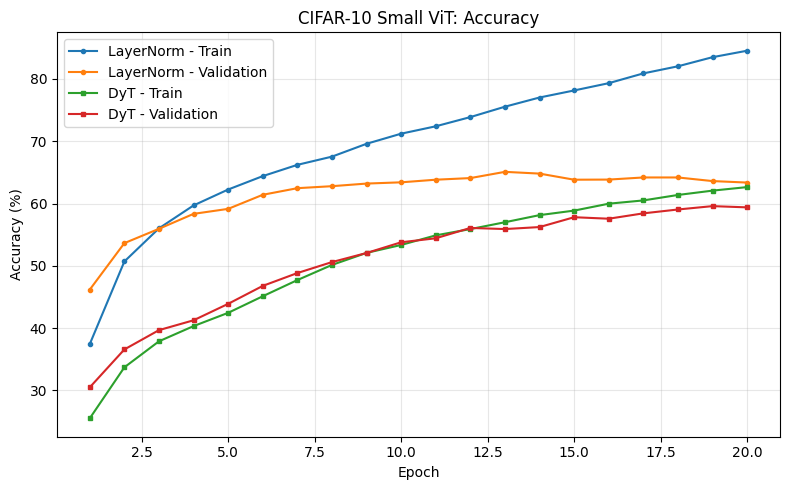

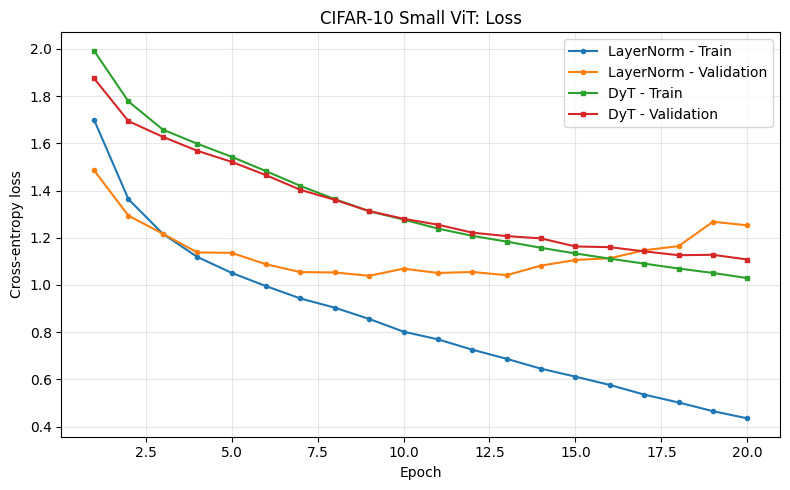

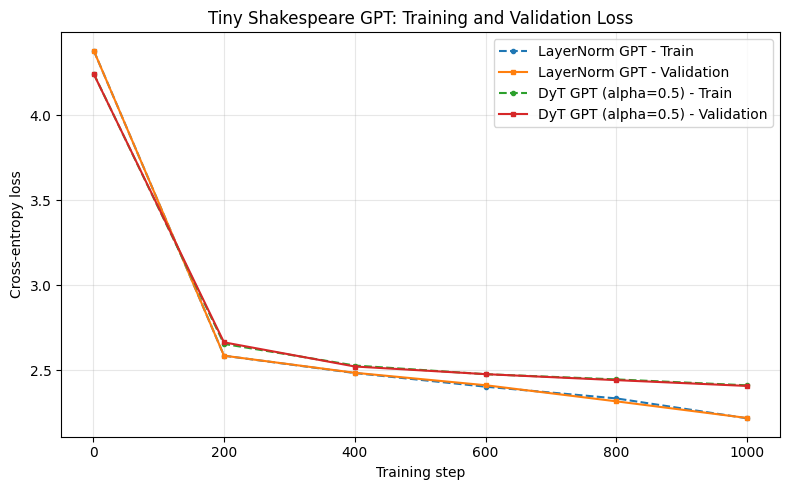

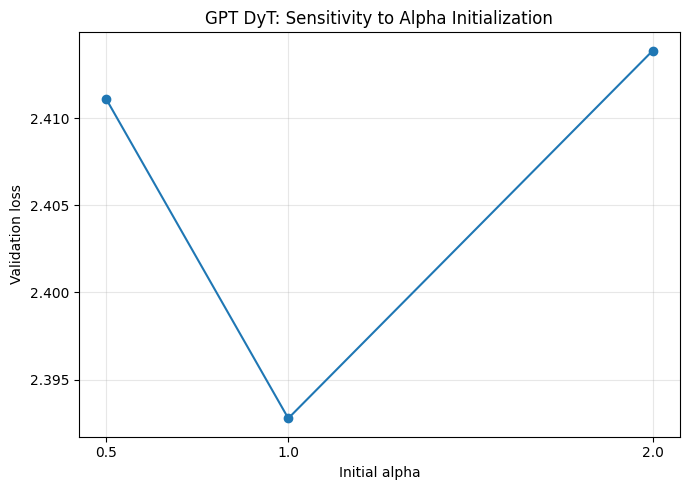


Saved figures:
 - gpt_alpha_ablation.png
 - gpt_loss.png
 - vit_accuracy.png
 - vit_loss.png


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

os.makedirs("project_figures", exist_ok=True)

# --------------------------------------------------
# Figure 1: ViT accuracy over 20 epochs
# --------------------------------------------------
epochs = range(1, len(history_ln_20["train_accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, np.array(history_ln_20["train_accuracy"]) * 100,
         marker="o", markersize=3, label="LayerNorm - Train")
plt.plot(epochs, np.array(history_ln_20["val_accuracy"]) * 100,
         marker="o", markersize=3, label="LayerNorm - Validation")
plt.plot(epochs, np.array(history_dyt_20["train_accuracy"]) * 100,
         marker="s", markersize=3, label="DyT - Train")
plt.plot(epochs, np.array(history_dyt_20["val_accuracy"]) * 100,
         marker="s", markersize=3, label="DyT - Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CIFAR-10 Small ViT: Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("project_figures/vit_accuracy.png", dpi=300)
plt.show()


# --------------------------------------------------
# Figure 2: ViT loss over 20 epochs
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_ln_20["train_loss"],
         marker="o", markersize=3, label="LayerNorm - Train")
plt.plot(epochs, history_ln_20["val_loss"],
         marker="o", markersize=3, label="LayerNorm - Validation")
plt.plot(epochs, history_dyt_20["train_loss"],
         marker="s", markersize=3, label="DyT - Train")
plt.plot(epochs, history_dyt_20["val_loss"],
         marker="s", markersize=3, label="DyT - Validation")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CIFAR-10 Small ViT: Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("project_figures/vit_loss.png", dpi=300)
plt.show()


# --------------------------------------------------
# Figure 3: GPT training and validation loss
# --------------------------------------------------
plt.figure(figsize=(8, 5))

for result, label in [
    (result_ln, "LayerNorm GPT"),
    (result_dyt, "DyT GPT (alpha=0.5)")
]:
    steps = [item["step"] for item in result["history"]]
    train_losses = [item["train_loss"] for item in result["history"]]
    val_losses = [item["val_loss"] for item in result["history"]]

    plt.plot(steps, train_losses, marker="o", markersize=3,
             linestyle="--", label=f"{label} - Train")
    plt.plot(steps, val_losses, marker="s", markersize=3,
             label=f"{label} - Validation")

plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Shakespeare GPT: Training and Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("project_figures/gpt_loss.png", dpi=300)
plt.show()


# --------------------------------------------------
# Figure 4: GPT alpha initialization ablation
# --------------------------------------------------
alpha_df = pd.read_csv("gpt_alpha_ablation.csv")
alpha_df = alpha_df.sort_values("Initial alpha")

plt.figure(figsize=(7, 5))
plt.plot(
    alpha_df["Initial alpha"],
    alpha_df["Validation loss"],
    marker="o",
    label="Validation loss"
)
plt.xlabel("Initial alpha")
plt.ylabel("Validation loss")
plt.title("GPT DyT: Sensitivity to Alpha Initialization")
plt.xticks(alpha_df["Initial alpha"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("project_figures/gpt_alpha_ablation.png", dpi=300)
plt.show()


# --------------------------------------------------
# List generated figures
# --------------------------------------------------
print("\nSaved figures:")
for filename in sorted(os.listdir("project_figures")):
    print(" -", filename)


In [ ]:

import os
import json
import pandas as pd

os.makedirs("results", exist_ok=True)

# 1. ViT comparison: final test results
vit_comparison = pd.DataFrame([
    {
        "Model": "Small ViT - LayerNorm",
        "Normalization": "LayerNorm",
        "Test loss": 1.0413,
        "Test accuracy (%)": 65.12,
        "Training epochs": 20,
        "Parameters": 281226
    },
    {
        "Model": "Small ViT - DyT",
        "Normalization": "DyT",
        "Initial alpha": 0.5,
        "Test loss": 1.1312,
        "Test accuracy (%)": 58.81,
        "Training epochs": 20,
        "Parameters": 281231
    }
])
vit_comparison.to_csv("results/vit_comparison.csv", index=False)

# 2. ViT alpha ablation: validation results
vit_alpha = pd.DataFrame([
    {
        "Initial alpha": r["alpha_init"],
        "Best epoch": r["best_epoch"],
        "Validation accuracy (%)": round(
            r["best_val_accuracy"] * 100, 2
        ),
        "Validation loss": round(r["best_val_loss"], 4),
        "Mean epoch time (s)": round(r["mean_epoch_seconds"], 2)
    }
    for r in ablation_results
])
vit_alpha.to_csv("results/vit_alpha_ablation.csv", index=False)

# 3. GPT comparison
gpt_comparison = pd.DataFrame([
    {
        "Model": "Small GPT - LayerNorm",
        "Normalization": "LayerNorm",
        "Validation loss": result_ln["validation_loss"],
        "Perplexity": result_ln["perplexity"],
        "Training time (s)": result_ln["training_seconds"],
        "Training steps": MAX_STEPS,
        "Parameters": 298305
    },
    {
        "Model": "Small GPT - DyT",
        "Normalization": "DyT",
        "Initial alpha": 0.5,
        "Validation loss": result_dyt["validation_loss"],
        "Perplexity": result_dyt["perplexity"],
        "Training time (s)": result_dyt["training_seconds"],
        "Training steps": MAX_STEPS,
        "Parameters": 298310
    }
])
gpt_comparison.to_csv("results/gpt_comparison.csv", index=False)

# 4. GPT alpha ablation
gpt_alpha = pd.read_csv("gpt_alpha_ablation.csv")
gpt_alpha.to_csv("results/gpt_alpha_ablation.csv", index=False)

# 5. Experiment configuration
experiment_config = {
    "paper": "Transformers without Normalization",
    "method": "Dynamic Tanh (DyT)",
    "framework": "PyTorch",
    "environment": {
        "device": str(device),
        "python_and_torch_versions": "Record using the next cell"
    },
    "vit": {
        "dataset": "CIFAR-10",
        "image_size": 32,
        "patch_size": 4,
        "embedding_dim": 128,
        "attention_heads": 4,
        "transformer_blocks": 2,
        "mlp_dim": 256,
        "batch_size": 128,
        "epochs_main_comparison": 20,
        "learning_rate": 0.0003,
        "optimizer": "AdamW",
        "weight_decay": 0.05,
        "dyt_alpha_main": 0.5,
        "alpha_ablation": [0.1, 0.5, 1.0, 2.0]
    },
    "gpt": {
        "dataset": "Tiny Shakespeare",
        "tokenization": "Character-level",
        "vocabulary_size": vocab_size,
        "block_size": BLOCK_SIZE,
        "embedding_dim": 128,
        "attention_heads": 4,
        "transformer_blocks": 2,
        "mlp_dim": 256,
        "batch_size": BATCH_SIZE,
        "training_steps": MAX_STEPS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "AdamW",
        "weight_decay": 0.01,
        "gradient_clipping": 1.0,
        "dyt_alpha_main": 0.5,
        "alpha_ablation": [0.5, 1.0, 2.0]
    },
    "notes": [
        "Reduced-scale experiments, not an exact reproduction of all paper results.",
        "ViT alpha ablation uses validation accuracy after five epochs.",
        "GPT alpha ablation uses validation loss and perplexity after 1000 steps."
    ]
}

with open("results/experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

# 6. Headline summary
summary = {
    "vit": {
        "layernorm_test_accuracy_percent": 65.12,
        "dyt_alpha_0_5_test_accuracy_percent": 58.81,
        "best_test_accuracy_among_vit_comparison": "LayerNorm"
    },
    "gpt": {
        "layernorm_validation_loss": result_ln["validation_loss"],
        "layernorm_perplexity": result_ln["perplexity"],
        "dyt_alpha_0_5_validation_loss": result_dyt["validation_loss"],
        "dyt_alpha_0_5_perplexity": result_dyt["perplexity"],
        "best_validation_loss_among_gpt_comparison": "LayerNorm"
    },
    "best_vit_alpha_in_short_ablation": 2.0,
    "best_gpt_alpha_among_tested_values": 1.0
}

with open("results/summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Created results files:")
for filename in sorted(os.listdir("results")):
    print(" -", filename)

print("\nViT comparison:")
display(vit_comparison)

print("\nGPT comparison:")
display(gpt_comparison.round(4))


Created results files:
 - experiment_config.json
 - gpt_alpha_ablation.csv
 - gpt_comparison.csv
 - summary.json
 - vit_alpha_ablation.csv
 - vit_comparison.csv

ViT comparison:


,Model,Normalization,Test loss,Test accuracy (%),Training epochs,Parameters,Initial alpha
0,Small ViT - LayerNorm,LayerNorm,1.0413,65.12,20,281226,NaN
1,Small ViT - DyT,DyT,1.1312,58.81,20,281231,0.5



GPT comparison:


,Model,Normalization,Validation loss,Perplexity,Training time (s),Training steps,Parameters,Initial alpha
0,Small GPT - LayerNorm,LayerNorm,2.2218,9.2242,18.0622,1000,298305,NaN
1,Small GPT - DyT,DyT,2.4111,11.1463,16.7902,1000,298310,0.5


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

# Destination in Google Drive
PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "transformers_without_normalization_dyt"
)

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/figures", exist_ok=True)

# Copy experiment results
shutil.copytree(
    "/content/results",
    f"{PROJECT_DIR}/results",
    dirs_exist_ok=True
)

# Copy generated plots
shutil.copytree(
    "/content/project_figures",
    f"{PROJECT_DIR}/figures",
    dirs_exist_ok=True
)

print("Project results and figures saved to:")
print(PROJECT_DIR)

print("\nResults:")
print(os.listdir(f"{PROJECT_DIR}/results"))

print("\nFigures:")
print(os.listdir(f"{PROJECT_DIR}/figures"))


Mounted at /content/drive
Project results and figures saved to:
/content/drive/MyDrive/transformers_without_normalization_dyt

Results:
['summary.json', 'experiment_config.json', 'vit_comparison.csv', 'gpt_comparison.csv', 'vit_alpha_ablation.csv', 'gpt_alpha_ablation.csv']

Figures:
['gpt_loss.png', 'vit_accuracy.png', 'gpt_alpha_ablation.png', 'vit_loss.png']


In [ ]:

import os
import torch

CHECKPOINT_DIR = f"{PROJECT_DIR}/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Save ViT checkpoints
torch.save(
    baseline_20.state_dict(),
    f"{CHECKPOINT_DIR}/vit_layernorm.pt"
)
torch.save(
    dyt_20.state_dict(),
    f"{CHECKPOINT_DIR}/vit_dyt_alpha_0_5.pt"
)

# Save GPT checkpoints
torch.save(
    result_ln["model"].state_dict(),
    f"{CHECKPOINT_DIR}/gpt_layernorm.pt"
)
torch.save(
    result_dyt["model"].state_dict(),
    f"{CHECKPOINT_DIR}/gpt_dyt_alpha_0_5.pt"
)

print("Saved model checkpoints:")
print(os.listdir(CHECKPOINT_DIR))


Saved model checkpoints:
['vit_layernorm.pt', 'vit_dyt_alpha_0_5.pt', 'gpt_layernorm.pt', 'gpt_dyt_alpha_0_5.pt']
